# rung quickstart

`rung` splits a dimensionality-scaling exponent into a **floor**, what random subsets of the same sizes return through the same estimator, and a **shift** that a declared label adds to it, and says what carries the shift. This notebook runs it on a toy population in a minute, then shows the commands for a real recording and a language model. It runs in Jupyter, VS Code or Colab; the [README](https://github.com/adilamin89/structure-in-the-zoom) has the reading rules.

In [1]:
try:
    import rung
except ImportError:
    %pip install -q git+https://github.com/adilamin89/structure-in-the-zoom
    import rung
print('rung', rung.__version__)

rung 1.10.0


## 1. A toy population

Eight classes of 64 samples over 64 features; each class triples the variance of its own four features, so the classes differ in their fluctuations and not in their means.

In [2]:
import numpy as np
rng = np.random.default_rng(0)
X = rng.standard_normal((512, 64))
y = np.repeat(np.arange(8), 64)
X *= 1 + 2 * (y[:, None] == np.arange(64)[None, :] // 4)     # class c triples features 4c to 4c + 3
np.save('X.npy', X); np.save('labels.npy', y)

In [3]:
!rung data X.npy labels.npy --decompose --out toy.json --plot toy.png > toy.log && tail -n 3 toy.log

  samples per class 64 against each class's own fluctuation dimension (PR of its residuals) 15.7 to 18.1, median 17.6; PR(W) 51.3, which pools the classes (README rule 8: the within-class part needs each class sampled beyond its own fluctuation dimension; --account prints the sampling term)
wrote toy.json
wrote toy.png


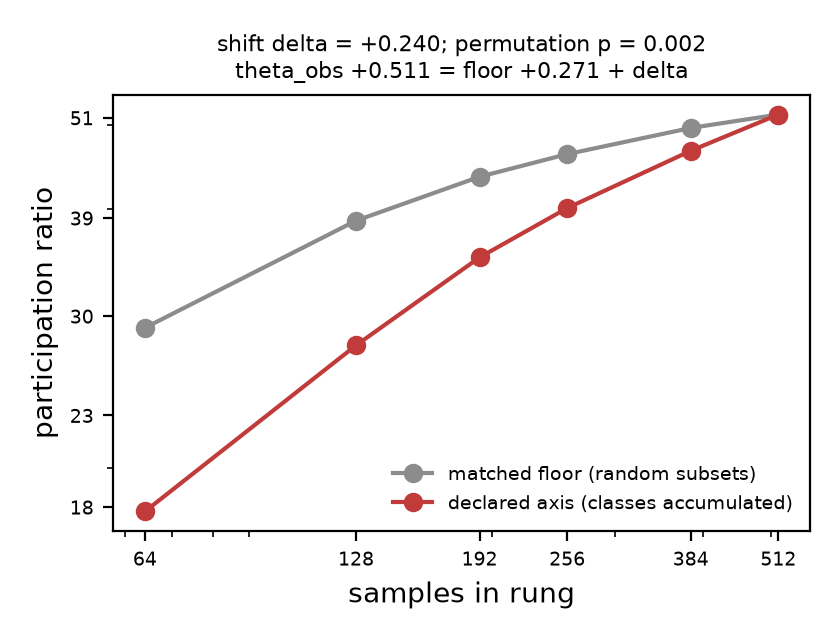

In [4]:
from IPython.display import Image
Image('toy.png', width=420)

The declared ladder (classes added one by one) climbs faster than its floor: the shift is positive. The reading:

In [5]:
!rung summarize toy.json

theta_obs = +0.511 = floor +0.271 + shift +0.240 (8 classes, rungs [64, 128, 192, 256, 384, 512]); the floor's standard error 0.003 (20 draws) is the uncertainty the shift inherits from it
declared order: z = +20.2, two-sided Monte Carlo p = 0.002 (resolution 0.002); label-linked at p < 0.05
order-averaged shift +0.252 (SD over orders 0.021), p = 0.002; same sign as the declared order
per-rung log-PR deficit below the floor, by classes accumulated 1: -0.491, 2: -0.333, 3: -0.216, 4: -0.144, 6: -0.061, 8: +0.000
share of the climb remaining after 4 of 8 classes: 0.29
split (Section 5): within-class part D +0.212 + class-mean part (Tb + Cb + Cx) +0.028 = shift +0.240 (decompose's own floor draws)
sampling: 64 samples per class against each class's own fluctuation dimension 15.7 to 18.1 (median 17.6); PR(W) 51.3 pools the classes
sign law (Eq. 3): full-set class-mean remainder c +0.002, negative exactly when PR(W)/PR(B) = 8.4 exceeds 1 + 2(1 - a)/beta = 22.0 (a 0.86, beta 0.013); its sign

`rung report` writes the same as one self-contained page, `toy.html`, to open in a browser or share (in Colab: the Files panel, then download).

In [6]:
!rung report toy.json

wrote toy.html


## 2. The same from Python

In [7]:
from rung import zoom, decompose, summarize_data

r = zoom(X, y)                     # floor, shift, permutation p, order-averaged shift
r['decompose'] = decompose(X, y)   # within-class and class-mean parts
print(f"theta_obs {r['theta_obs']:+.3f} = floor {r['theta_floor']:+.3f} + shift {r['delta']:+.3f}, p = {r['p_two']:.3f}")
rep = summarize_data(r, verbose=False)
print(rep['lines'][-3])

theta_obs +0.511 = floor +0.271 + shift +0.240, p = 0.002
split (Section 5): within-class part D +0.221 + class-mean part (Tb + Cb + Cx) +0.025 = shift +0.246 (decompose's own floor draws)


## 3. Your own data

Any samples-by-features array with one integer label per row: trials by neurons, prompts by hidden units, images by channels. Save them as `.npy` and run the two commands above. At recording scale (thousands of rows) start with `--n-perm 100 --k-orders 10 --floor-draws 5`, then rerun with the defaults for the numbers you report.

## 4. A recording: GT3 (Appendix M of the paper)

4,442 drifting-grating presentations by 11,311 mouse V1 neurons from the Figshare release 8279387 (489 MB). Not run here: the full command takes about 70 minutes on one laptop core; the first-look settings below take a fraction of that.

In [ ]:
!curl -sL -o gratings_drifting_GT3_2019_04_05_1.npy https://ndownloader.figshare.com/files/15479240
d = np.load('gratings_drifting_GT3_2019_04_05_1.npy', allow_pickle=True).item()
np.save('gt3_X.npy', np.asarray(d['sresp'], np.float32).T)          # presentations by neurons
phi = np.asarray(d['istim'], float) % (2 * np.pi)                   # drift direction in radians
np.save('gt3_labels.npy', np.clip(np.digitize(phi, np.linspace(0, 2 * np.pi, 9)) - 1, 0, 7))

In [ ]:
!rung data gt3_X.npy gt3_labels.npy --sectors --decompose --n-perm 100 --k-orders 10 --floor-draws 5 --out gt3.json
!rung report gt3.json

## 5. A language model

Every layer of Pythia-160M on the paper's topic axis (8 topics, 32 prompts each). Needs the model extras and a clone for the axis file. Without `--match-last-token` this is a first look; add it before reading a lift as more than its final tokens (Appendix M: about 19 minutes on one laptop core with it).

In [ ]:
!git clone -q https://github.com/adilamin89/structure-in-the-zoom
%pip install -q -e './structure-in-the-zoom[models]'
!rung llm --model EleutherAI/pythia-160m --axis structure-in-the-zoom/axes/world_knowledge32.json --out lm.json
!rung report lm.json